
 
<table style="width: 100%; border-collapse: collapse; border-bottom: 4px solid #003366;">
    <tr style="border: none;">
        <td style="border: none; text-align: left; vertical-align: middle; padding-bottom: 15px;">
            <h1 style="color: #003366; font-family: 'Helvetica', sans-serif; margin-top: 0; margin-bottom: 5px;">IMT3410: M&eacute;todos para Ecuaciones Diferenciales</h1>
            <h2 style="color: #555; margin-top: 10px; margin-bottom: 10px;">Cap&iacute;tulo 3: Motivaci&oacute;n Leyes de Conservaci&oacute;n</h2>
            <p style="margin: 2px 0;"><b>Profesor:</b> Manuel A. Sánchez </p>
            <p style="margin: 2px 0;"><b>Institución:</b> Instituto de Ingenier&iacute;a Matemática y Coputacional, Pontificia Universidad Católica de Chile</p>
        </td>
        <td style="border: none; text-align: right; vertical-align: middle; padding-bottom: 15px; width: 260px;">
            <!-- <img src="../source/FacMatematicas-15.png" alt="Logo UC" width="400" style="margin-bottom: 8px;"> -->
            <br>
            <a href="https://colab.research.google.com/github/ManuelSanchezUribe/ManuelSanchezUribe.github.io/blob/main/IMT3410/Notebooks_2026/03_Capitulo_Motivacion.ipynb" target="_blank">
                <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab" width="120">
            </a>
        </td>
    </tr>
</table>
<br>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d
from scipy.optimize import fsolve
# !pip install ipympl

## Ecuacion de adveccion - ley de conservacion lineal

Analizamos la ecuación de advección en dimensión 1, con **coeficiente de advección constante**.
$$
\frac{\partial q}{\partial t}(x,t) + a \frac{\partial q}{\partial x}(x,t) = 0, \quad x\in (a,b), t\geq 0
$$


In [2]:
# condicion inicial
q0 = lambda x: np.sin(np.pi*x)

# coeficiente de adveccion
a = 1.0

# solucion de la ecuacion de adveccion
q = lambda x,t: q0(x-a*(t-0))

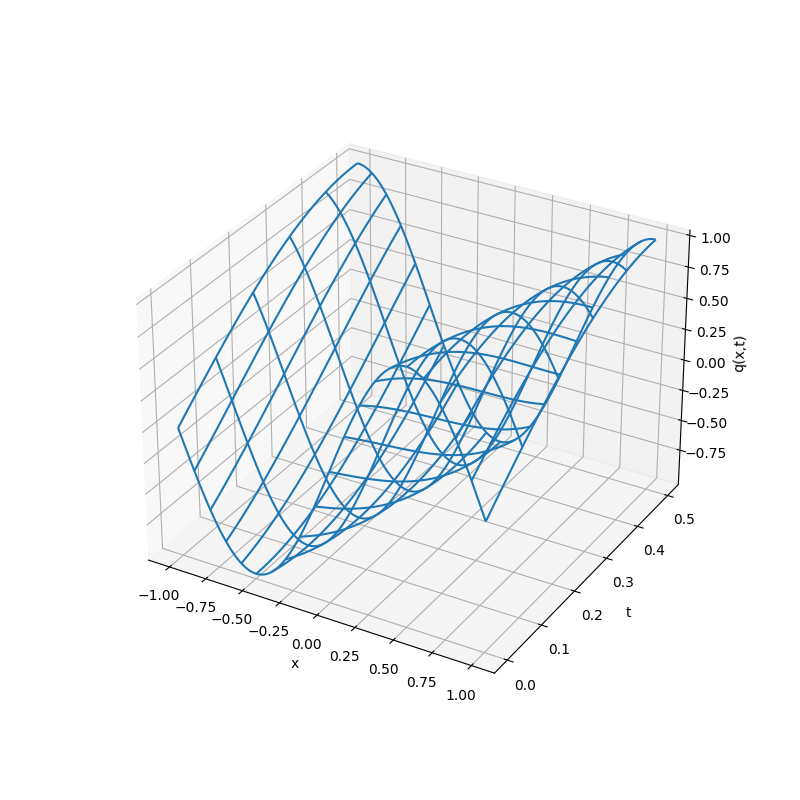

In [3]:
%matplotlib widget
xplot = np.linspace(-1,1,200)
ti = 0.1
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')
#plt.plot(xplot, q(xplot,ti))

tplot=np.linspace(0,.5,50)
# Grab some test data.
X,T = np.meshgrid(xplot, tplot)

Z = q(X,T)
# Plot a basic wireframe.
ax.plot_wireframe(X, T, Z, rstride=10, cstride=10)
ax.set(xlabel='x',ylabel='t',zlabel='q(x,t)')
plt.show()

Analizamos la ecuación de advección en dimensión 1, con **coeficiente de advección variable en espacio**.
$$
\frac{\partial q}{\partial t}(x,t) + a(x) \frac{\partial q}{\partial x}(x,t) = 0, \quad x\in (a,b), t\geq 0
$$

In [4]:
q0 = lambda x: np.sin(np.pi*x)
# coeficiente de adveccion
a = lambda x: (1/np.pi)*np.sin(np.pi*x-1)

#solucion de la ecuacion de adveccion
q = lambda x,t: np.sin(2*np.arctan(np.exp(-t)*np.tan((np.pi*x-1)/2))+1 )

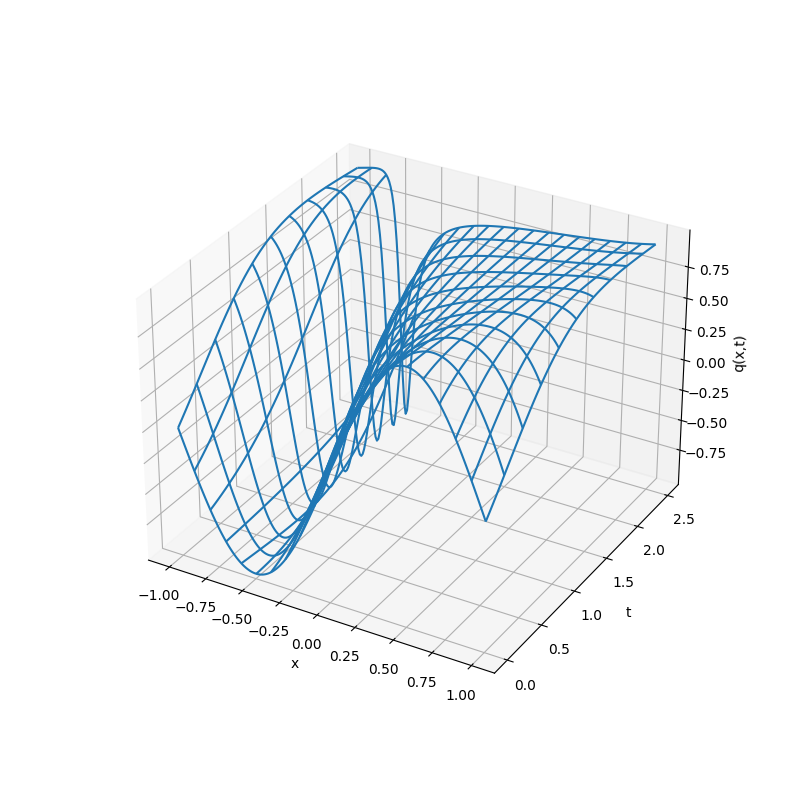

In [5]:
%matplotlib widget
xplot = np.linspace(-1,1,200)
ti = 0.1
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')
#plt.plot(xplot, q(xplot,ti))

tplot=np.linspace(0,2.5,50)
# Grab some test data.
X,T = np.meshgrid(xplot, tplot)

Z = q(X,T)
# Plot a basic wireframe.
ax.plot_wireframe(X, T, Z, rstride=5, cstride=10)
ax.set(xlabel='x',ylabel='t',zlabel='q(x,t)')
plt.show()

## Ecuacion de Burgers - ley de conservacion no lineal

In [6]:
q0 = lambda x: -np.sin(np.pi*x)
#solucion de la ecuacion de Burgers
fun = lambda q,x,t: q - q0(x-q*t)
q = lambda x,t: fsolve(lambda q: fun(q,x,t), q0(x))[0]

(50, 200)
(200, 50)


/home/msanchez/.local/lib/python3.8/site-packages/scipy/optimize/_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)
/home/msanchez/.local/lib/python3.8/site-packages/scipy/optimize/_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last five Jacobian evaluations.
  warnings.warn(msg, RuntimeWarning)


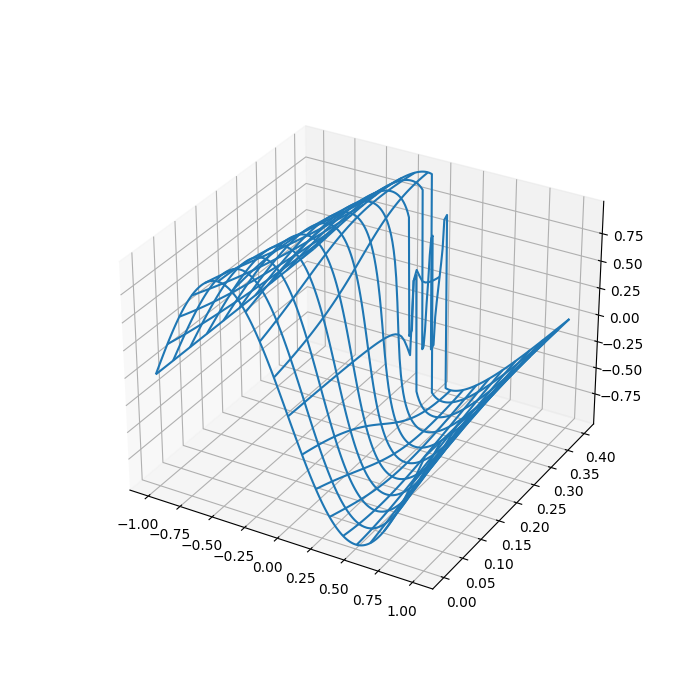

In [7]:
%matplotlib widget

xplot = np.linspace(-1,1,200)

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(projection='3d')
#plt.plot(xplot, q(xplot,ti))

tplot = np.linspace(0,0.4,50)
# Grab some test data.
X,T = np.meshgrid(xplot, tplot)
print(X.shape)
Z = np.zeros((xplot.size, tplot.size))
print(Z.shape)
for j in range(xplot.size):
    for n in range(tplot.size):
        Z[j,n] = q(xplot[j],tplot[n])
#Z = q(X,T)
#print(Z)
# Plot a basic wireframe.
ax.plot_wireframe(X, T, Z.T, rstride=5, cstride=10)

plt.show()

## Ecuacion de Burgers - problema de Riemann

$$
\frac{\partial u}{\partial t}(x,t) + \frac{\partial}{\partial x}(u^2/2)(x,t) = 0, \quad 
u_0(x) = 
\begin{cases} 
u_l & x<0 \\
u_R & x\geq 0
\end{cases}
$$

In [8]:
def u0Riemann(x,ul,ur):
    if x<0:
        return ul
    else:
        return ur

In [9]:
#solucion de la ecuacion de Burgers
ul = 0.5
ur = 1
u0 = lambda x: u0Riemann(x,ul,ur)
fun = lambda u,x,t: u - u0(x-u*t)
u = lambda x,t: fsolve(lambda u: fun(u,x,t), u0(x))[0]
u(0.1,0.2)

s = (ul+ur)*0.5
ushock = lambda x, t: u0(x-s*t)

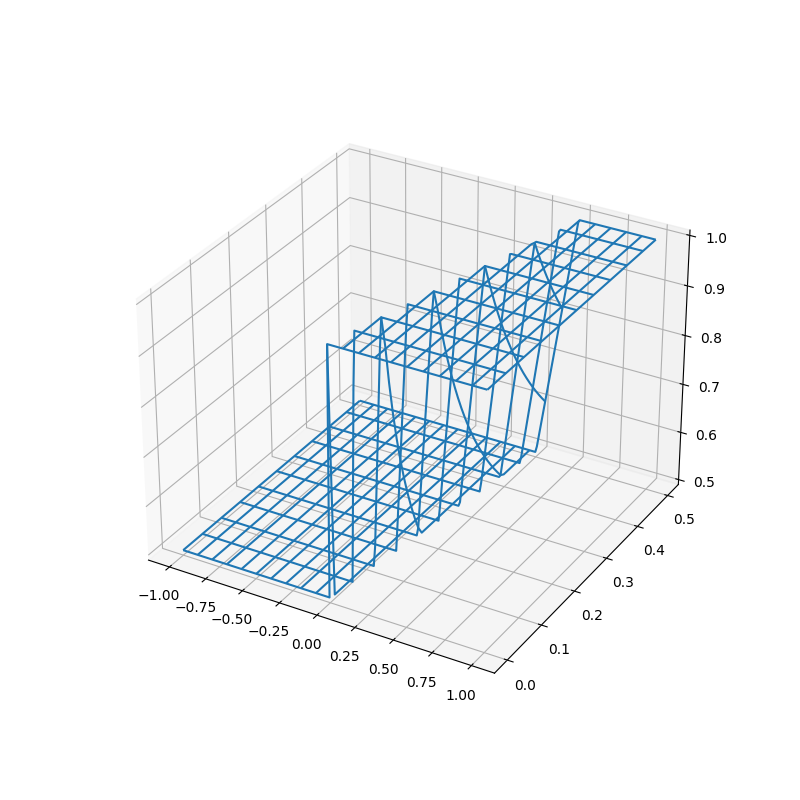

In [10]:
# %matplotlib widget
xplot = np.linspace(-1,1,200)

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')

tplot = np.linspace(0,0.5,50)
# ax.plot(xplot, u(xplot,tplot))

# Grab some test data.
X,T = np.meshgrid(xplot, tplot)
Z = np.ones((xplot.size, tplot.size))
Zshock = np.ones((xplot.size, tplot.size))
for j in range(xplot.size):
    for n in range(tplot.size):
        Z[j,n] = u(xplot[j],tplot[n])
        Zshock[j,n] = ushock(xplot[j],tplot[n])
# Plot a basic wireframe.
ax.plot_wireframe(X, T, Z.T, rstride=5, cstride=10)
# fig2 = plt.figure(figsize=(8,8))
# ax2 = fig.add_subplot(projection='3d')
# ax2.plot_wireframe(X, T, Zshock.T, rstride=5, cstride=10)
plt.show()

(50, 200)
(200, 50)


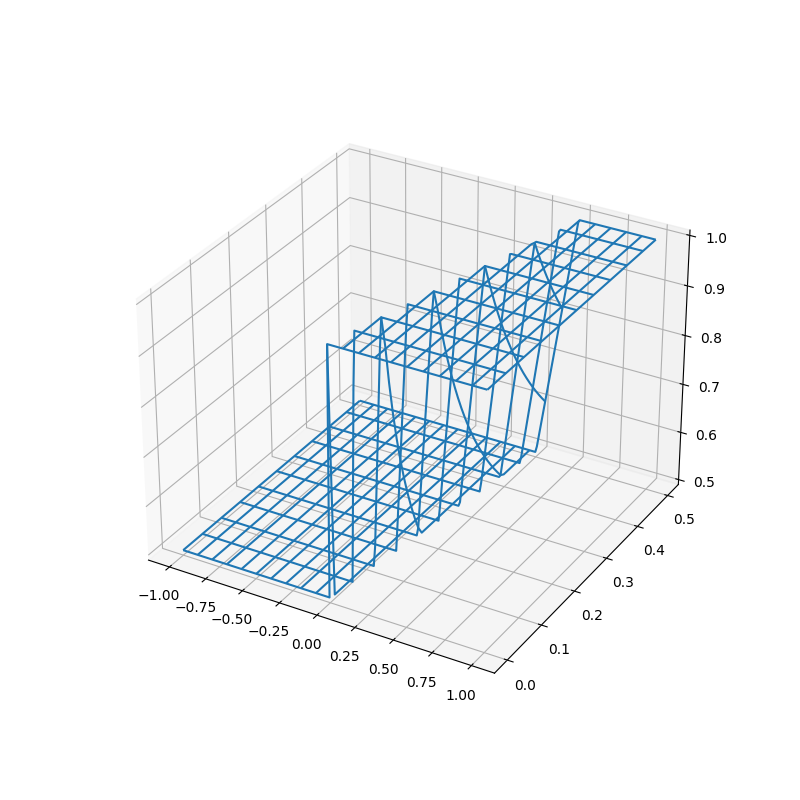

In [11]:
# %matplotlib widget

xplot = np.linspace(-1,1,200)

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')
#plt.plot(xplot, q(xplot,ti))

tplot = np.linspace(0,0.5,50)
# Grab some test data.
X,T = np.meshgrid(xplot, tplot)
print(X.shape)
Z = np.ones((xplot.size, tplot.size))
print(Z.shape)
for j in range(xplot.size):
    for n in range(tplot.size):
        Z[j,n] = u(xplot[j],tplot[n])
#Z = q(X,T)
#print(Z)
# Plot a basic wireframe.
ax.plot_wireframe(X, T, Z.T, rstride=5, cstride=10)

plt.show()